In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Data Cleaning

In [ ]:
WDI_data = pd.read_csv("WDI_Data_Raw.csv", encoding="cp1252")   #Panda assumes UTF-8 encoding but came across an en dash in the csv file which is not part of it.

display(WDI_data)

,Country Name,Country Code,Series Name,Series Code,2000 [YR2000],2001 [YR2001],2002 [YR2002],2003 [YR2003],2004 [YR2004],2005 [YR2005],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Pakistan,PAK,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,4.260088011,3.651350171,2.594816684,5.401310873,7.83125557,7.276574436,...,6.573838,4.432626,6.151703,2.497637,-1.274087,6.513886,4.778107,-0.414936,3.081763,3.698427
1,Pakistan,PAK,Gross capital formation (% of GDP),NE.GDI.TOTL.ZS,16.31067792,15.99690874,14.96241043,15.31486559,15.65077071,16.26644379,...,15.935747,16.332891,17.068291,15.499645,14.815540,14.534692,15.560543,13.968147,13.199253,14.282808
2,Pakistan,PAK,"Foreign direct investment, net inflows (% of GDP)",BX.KLT.DINV.WD.GD.ZS,0.309595026,0.389106586,0.8435173,0.475207712,0.845585702,1.515750831,...,0.821350,0.735837,0.487746,0.696146,0.684695,0.616039,0.389981,0.608281,0.716885,0.454694
3,Pakistan,PAK,Current account balance (% of GDP),BN.CAB.XOKA.GD.ZS,-0.085440186,1.933180342,3.935733262,3.179620139,-0.617928013,-2.483462357,...,-2.292797,-4.769858,-5.295562,-2.666773,-0.216651,-3.524396,-3.258582,-0.308630,0.124893,-0.109990
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Data from database: World Development Indicators,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Last Updated: 11/11/2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Code,License Type,Indicator Name,Long definition,Source,Topic,Dataset,Unit of measure,Periodicity,Reference period,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
DF = WDI_data.copy() #Making a copy of the original data file as a safe measure

In [ ]:
DF_raw = pd.concat([DF.iloc[0:4, 2:3], DF.iloc[0:4, 4:]], axis=1)
display(DF_raw)

,Series Name,2000 [YR2000],2001 [YR2001],2002 [YR2002],2003 [YR2003],2004 [YR2004],2005 [YR2005],2006 [YR2006],2007 [YR2007],2008 [YR2008],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,GDP growth (annual %),4.260088011,3.651350171,2.594816684,5.401310873,7.83125557,7.276574436,6.051637676,4.44481434,2.120441043,...,6.573838,4.432626,6.151703,2.497637,-1.274087,6.513886,4.778107,-0.414936,3.081763,3.698427
1,Gross capital formation (% of GDP),16.31067792,15.99690874,14.96241043,15.31486559,15.65077071,16.26644379,18.28221416,17.53593622,17.99642261,...,15.935747,16.332891,17.068291,15.499645,14.815540,14.534692,15.560543,13.968147,13.199253,14.282808
2,"Foreign direct investment, net inflows (% of GDP)",0.309595026,0.389106586,0.8435173,0.475207712,0.845585702,1.515750831,2.639750062,3.035719338,2.689366561,...,0.821350,0.735837,0.487746,0.696146,0.684695,0.616039,0.389981,0.608281,0.716885,0.454694
3,Current account balance (% of GDP),-0.085440186,1.933180342,3.935733262,3.179620139,-0.617928013,-2.483462357,-4.168123958,-4.507961758,-7.741943515,...,-2.292797,-4.769858,-5.295562,-2.666773,-0.216651,-3.524396,-3.258582,-0.308630,0.124893,-0.109990


In [ ]:
TS = DF_raw.T   #Transposing to make a Series 
display(TS)

,0,1,2,3
Series Name,GDP growth (annual %),Gross capital formation (% of GDP),"Foreign direct investment, net inflows (% of GDP)",Current account balance (% of GDP)
2000 [YR2000],4.260088011,16.31067792,0.309595026,-0.085440186
2001 [YR2001],3.651350171,15.99690874,0.389106586,1.933180342
2002 [YR2002],2.594816684,14.96241043,0.8435173,3.935733262
2003 [YR2003],5.401310873,15.31486559,0.475207712,3.179620139
2004 [YR2004],7.83125557,15.65077071,0.845585702,-0.617928013
2005 [YR2005],7.276574436,16.26644379,1.515750831,-2.483462357
2006 [YR2006],6.051637676,18.28221416,2.639750062,-4.168123958
2007 [YR2007],4.44481434,17.53593622,3.035719338,-4.507961758
2008 [YR2008],2.120441043,17.99642261,2.689366561,-7.741943515


As we can see, after transposing panda sets the column names as 0,1,2,3 and first row as Series Name and Names of our Time Series 

To fix it, we set the columns as the first row, set the time series data part as the data that is starting from row 2 (python index of row 1), and then we also remove the [YR] part of the Series Name columns and convert the dates to integers


In [ ]:
TS.columns = TS.iloc[0]                         # Make first row as column names
TS = TS.iloc[1:]                                # Make the time series data start from row 2
TS.index = TS.index.str[:4].astype(int)         # Extract first 4 elements of the string of the index
TS.index.name = "Year"                          # Changed "Series Name" to "Years"
display(TS)

Series Name,GDP growth (annual %),Gross capital formation (% of GDP),"Foreign direct investment, net inflows (% of GDP)",Current account balance (% of GDP)
Year,,,,
2000,4.260088011,16.31067792,0.309595026,-0.085440186
2001,3.651350171,15.99690874,0.389106586,1.933180342
2002,2.594816684,14.96241043,0.8435173,3.935733262
2003,5.401310873,15.31486559,0.475207712,3.179620139
2004,7.83125557,15.65077071,0.845585702,-0.617928013
2005,7.276574436,16.26644379,1.515750831,-2.483462357
2006,6.051637676,18.28221416,2.639750062,-4.168123958
2007,4.44481434,17.53593622,3.035719338,-4.507961758
2008,2.120441043,17.99642261,2.689366561,-7.741943515


In [ ]:
# We do a check now to see if there are any missing values and what is the data type of our final Time Series
TS.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26 entries, 2000 to 2025
Data columns (total 4 columns):
 #   Column                                             Non-Null Count  Dtype 
---  ------                                             --------------  ----- 
 0   GDP growth (annual %)                              26 non-null     object
 1   Gross capital formation (% of GDP)                 26 non-null     object
 2   Foreign direct investment, net inflows (% of GDP)  26 non-null     object
 3   Current account balance (% of GDP)                 26 non-null     object
dtypes: object(4)
memory usage: 1.0+ KB


Because our series is stored as object, we would not be able to plot it, so we will convert all of it into float

In [ ]:
TS = TS.apply(pd.to_numeric, errors="coerce")
TS.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26 entries, 2000 to 2025
Data columns (total 4 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   GDP growth (annual %)                              26 non-null     float64
 1   Gross capital formation (% of GDP)                 26 non-null     float64
 2   Foreign direct investment, net inflows (% of GDP)  26 non-null     float64
 3   Current account balance (% of GDP)                 26 non-null     float64
dtypes: float64(4)
memory usage: 1.0 KB


This ends the data cleaning process

# Visualization

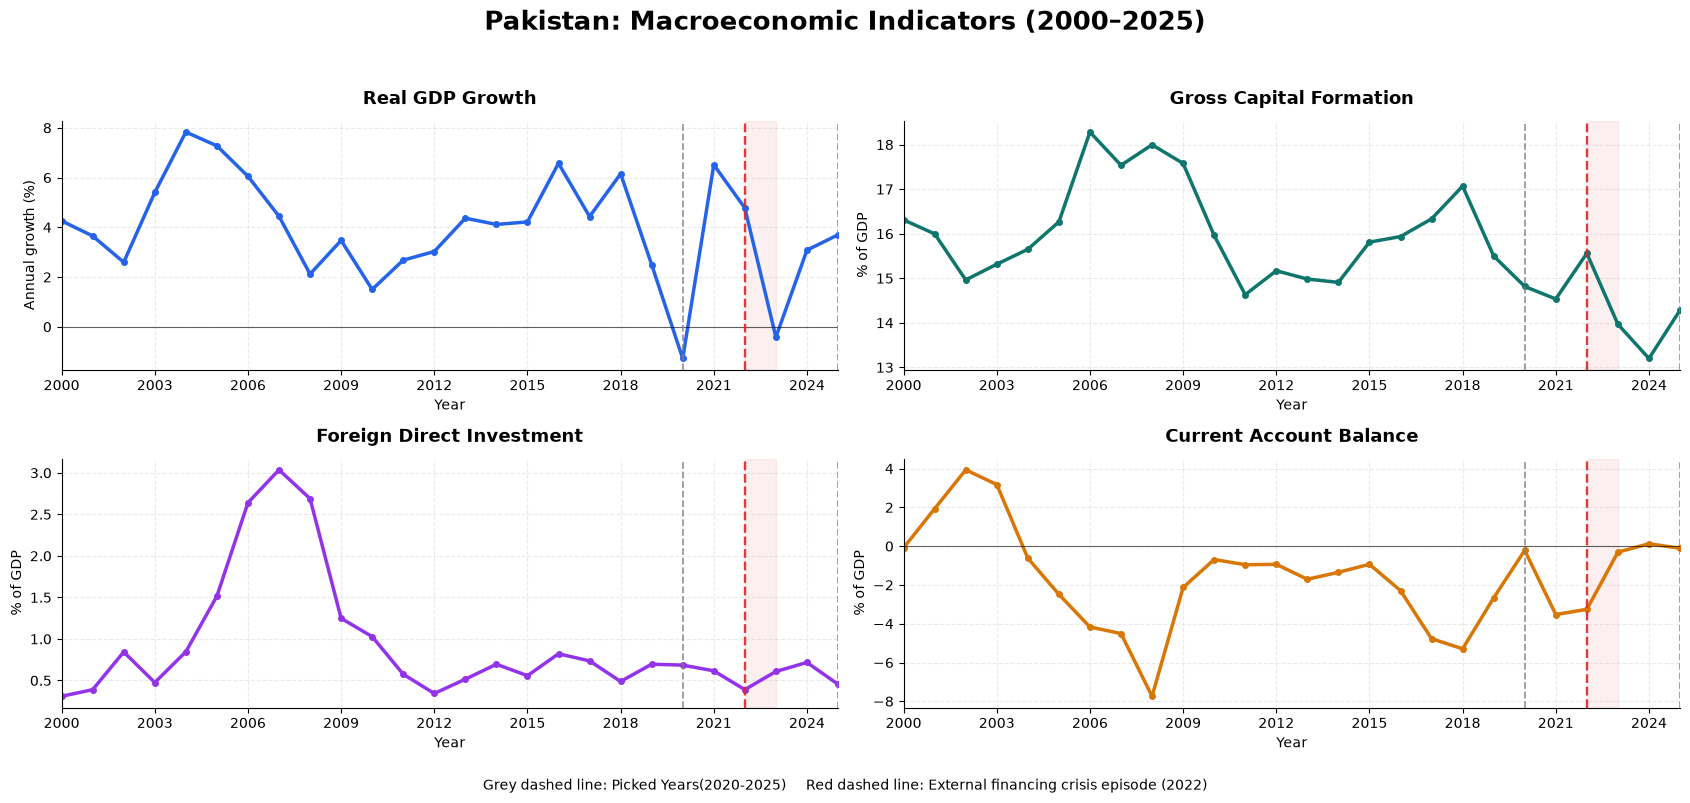

In [ ]:
import matplotlib.ticker as mtick

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(17, 8))

fig.suptitle(
    "Pakistan: Macroeconomic Indicators (2000–2025)",
    fontsize=19,
    fontweight="bold",
    y=0.99
)

# Individual colours
colors = {
    "gdp": "#2563EB",       # Blue
    "investment": "#0F766E",# Teal
    "fdi": "#9333EA",       # Purple
    "current": "#D97706"    # Amber
}

# Common formatting
def format_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Year", fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)

    ax.grid(True, linestyle="--", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_xlim(2000, 2025)
    ax.set_xticks(range(2000, 2026, 3))

    # Years marker
    ax.axvline(
        x=2020,
        color="grey",
        linestyle="--",
        linewidth=1.3,
        alpha=0.8
    )
    ax.axvline(
        x=2025,
        color="grey",
        linestyle="--",
        linewidth=1.3,
        alpha=0.8
    )

    # External financing crisis marker
    ax.axvline(
        x=2022,
        color="#DC2626",
        linestyle="--",
        linewidth=1.7,
        alpha=0.9
    )

    # Highlight main crisis episode
    ax.axvspan(
        2022, 2023,
        color="#DC2626",
        alpha=0.07
    )

# 1. GDP Growth
ax = axes[0, 0]

ax.plot(
    TS.index,
    TS["GDP growth (annual %)"],
    color=colors["gdp"],
    linewidth=2.5,
    marker="o",
    markersize=4
)

ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)

format_axis(ax, "Real GDP Growth", "Annual growth (%)")

# 2. Gross Capital Formation
ax = axes[0, 1]

ax.plot(
    TS.index,
    TS["Gross capital formation (% of GDP)"],
    color=colors["investment"],
    linewidth=2.5,
    marker="o",
    markersize=4
)

format_axis(ax, "Gross Capital Formation", "% of GDP")

# 3. Foreign Direct Investment
ax = axes[1, 0]

ax.plot(
    TS.index,
    TS["Foreign direct investment, net inflows (% of GDP)"],
    color=colors["fdi"],
    linewidth=2.5,
    marker="o",
    markersize=4
)

format_axis(ax, "Foreign Direct Investment", "% of GDP")

# 4. Current Account Balance
ax = axes[1, 1]

ax.plot(
    TS.index,
    TS["Current account balance (% of GDP)"],
    color=colors["current"],
    linewidth=2.5,
    marker="o",
    markersize=4
)

ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)

format_axis(ax, "Current Account Balance", "% of GDP")

# Add legend for event markers
fig.text(
    0.5, 0.015,
    "Grey dashed line: Picked Years(2020-2025)     "
    "Red dashed line: External financing crisis episode (2022)",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.045, 1, 0.96])

plt.show()


# Data handling


To make a fair comparison with IRF taken from dynare, we will have to see how our time series is behaving with respect to the steady state, to do that, we will use, 